In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

df = pd.read_csv('ML-Dataset_cleaned.csv')

# Удаляем ненужные для классификации столбцы
columns_to_drop = [
    'Profit_Std', 'CreditLimit_Norm', 'Category_Code', 'Job_Code',
    'Profit_Per_Unit', 'OrderItemQuantity', 'TotalItemQuantity',
    'ProductName', 'EmployeeJobTitle', 'Status'
]

df_clean = df.drop(columns=columns_to_drop, errors='ignore')

# Кодируем категориальные признаки
le_country = LabelEncoder()
df_clean['CountryName'] = le_country.fit_transform(df_clean['CountryName'])

# Целевая переменная
le_target = LabelEncoder()
y = le_target.fit_transform(df_clean['CategoryName'])
X = df_clean.drop(columns=['CategoryName'])

print(f"Признаки: {list(X.columns)}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"\nРазмер обучающей выборки: {X_train_raw.shape}")
print(f"Размер тестовой выборки: {X_test_raw.shape}")
print(f"\nРаспределение классов в обучающей выборке:")
for i, class_name in enumerate(le_target.classes_):
    count = np.sum(y_train == i)
    pct = count / len(y_train) * 100
    print(f"  {class_name}: {count} ({pct:.1f}%)")

# Данные для деревьев (без стандартизации)
X_train_tree = X_train_raw
X_test_tree = X_test_raw

# Создаем отдельный scaler для метрических методов
scaler = StandardScaler()
X_train_metric = scaler.fit_transform(X_train_raw)
X_test_metric = scaler.transform(X_test_raw)

# Преобразуем обратно в DataFrame для удобства
X_train_metric = pd.DataFrame(X_train_metric, columns=X.columns)
X_test_metric = pd.DataFrame(X_test_metric, columns=X.columns)


Признаки: ['CountryName', 'ProductStandardCost', 'Profit', 'ProductListPrice', 'CustomerCreditLimit', 'PerUnitPrice']

Размер обучающей выборки: (300, 6)
Размер тестовой выборки: (100, 6)

Распределение классов в обучающей выборке:
  CPU: 67 (22.3%)
  Mother Board: 59 (19.7%)
  RAM: 26 (8.7%)
  Storage: 95 (31.7%)
  Video Card: 53 (17.7%)



------------------------------------------------------------
1. Дерево решений
------------------------------------------------------------

1.1 Базовое дерево:
  Accuracy: 0.8000
  F1-score (macro): 0.8050
  F1-score (weighted): 0.8009


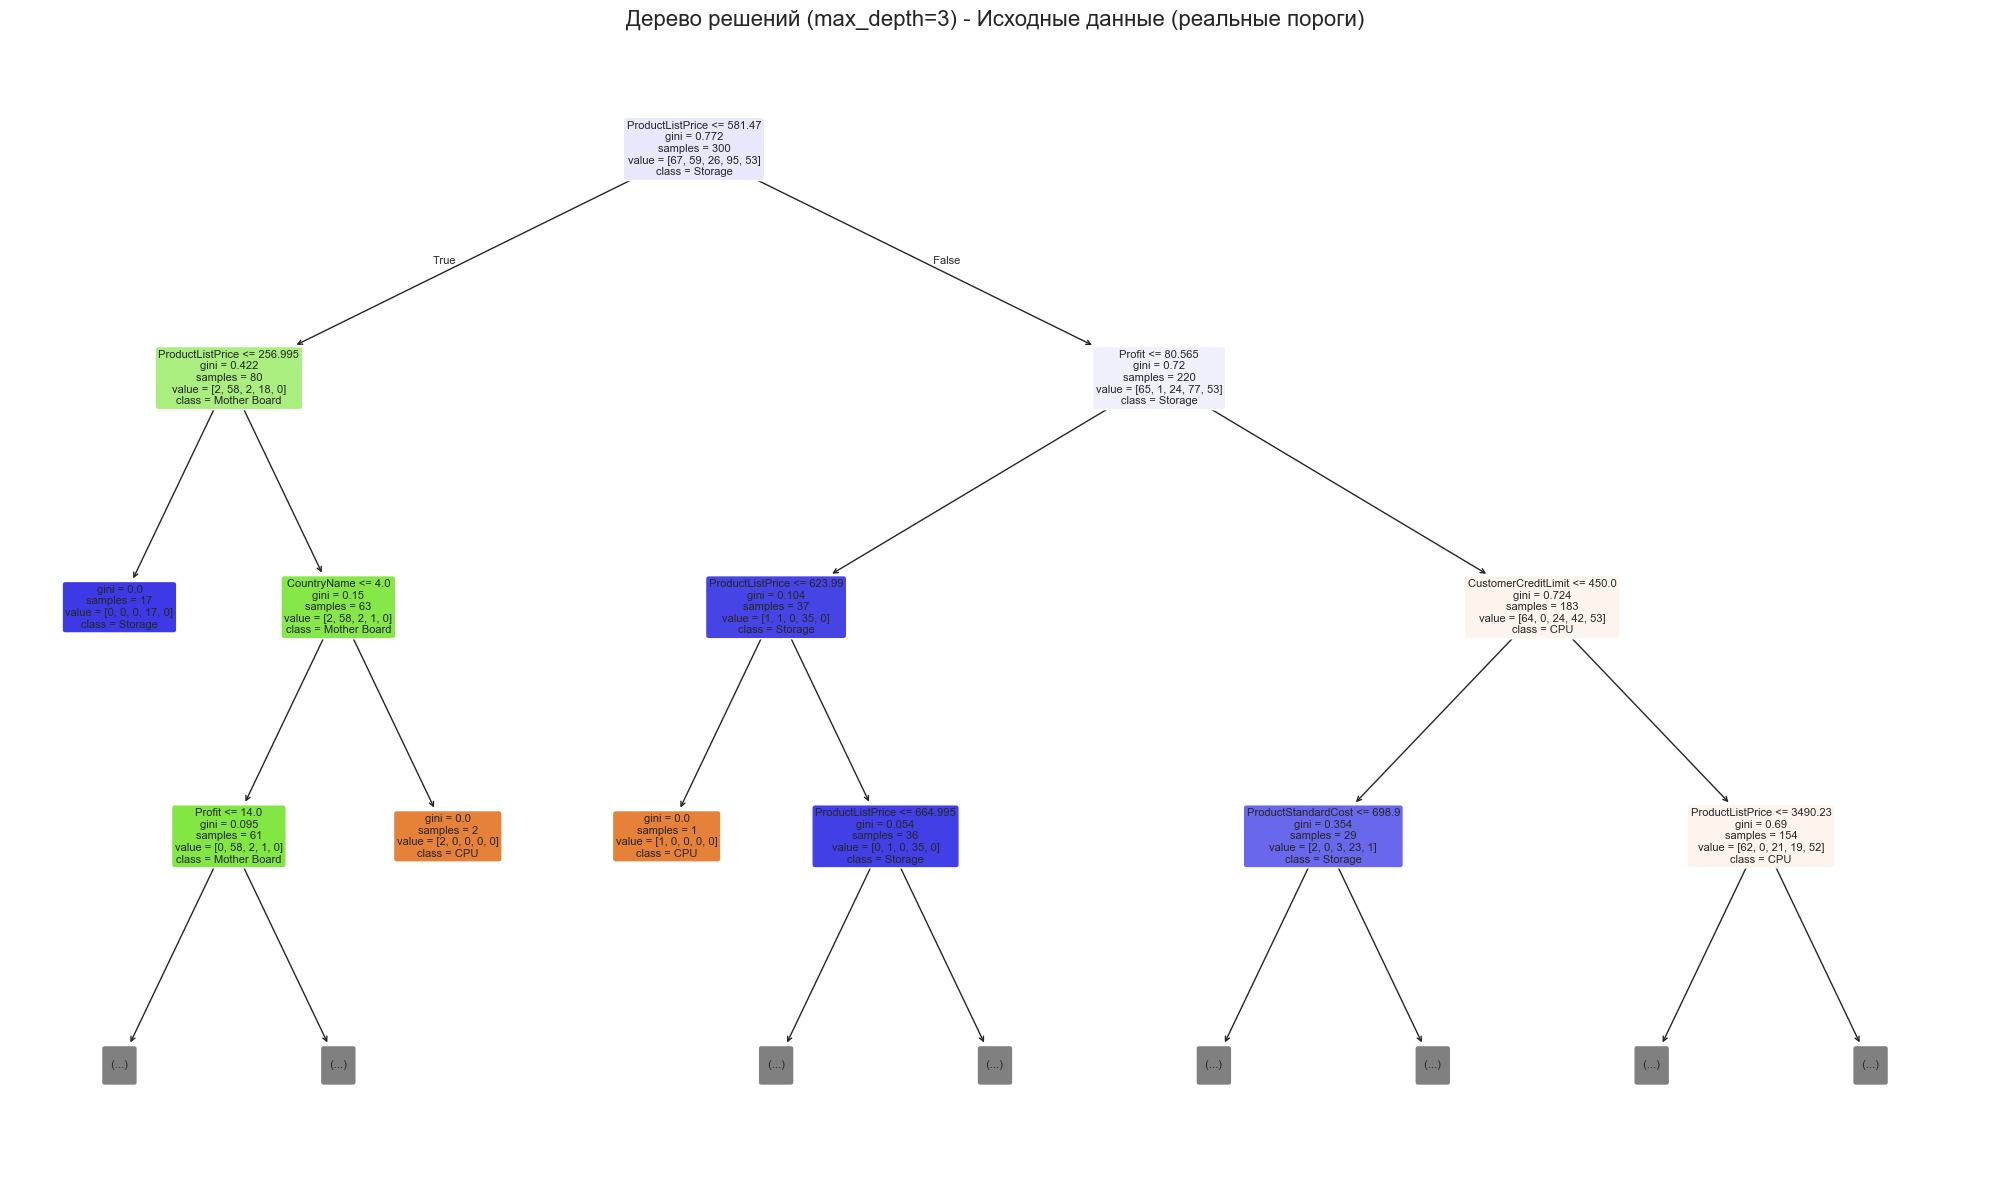


Информация о корневом узле дерева (реальные единицы измерения):
  Признак: ProductListPrice
  Порог: 581.47
  Количество объектов в левом поддереве: 80
  Количество объектов в правом поддереве: 17

1.3 Настройка гиперпараметров...
Fitting 5 folds for each of 192 candidates, totalling 960 fits

  Лучшие параметры: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
  Лучшая кросс-валидационная точность: 0.8267

1.4 Оценка качества на тестовой выборке:
  Accuracy: 0.8000
  F1-мера (макро): 0.8131
  F1-мера (взвешенная): 0.8036


In [78]:
print("\n" + "-"*60)
print("1. Дерево решений")
print("-"*60)

# Построение базовой модели
dt_base = DecisionTreeClassifier(random_state=42)
dt_base.fit(X_train_tree, y_train)
y_pred_base = dt_base.predict(X_test_tree)

print(f"\n1.1 Базовое дерево:")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_base):.4f}")
print(f"  F1-score (macro): {f1_score(y_test, y_pred_base, average='macro'):.4f}")
print(f"  F1-score (weighted): {f1_score(y_test, y_pred_base, average='weighted'):.4f}")

# 1.2 Визуализация дерева
plt.figure(figsize=(20, 12))
plot_tree(
    dt_base,
    max_depth=3,
    feature_names=X.columns,
    class_names=le_target.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Дерево решений (max_depth=3) - Исходные данные (реальные пороги)", fontsize=16)
plt.tight_layout()
plt.show()

# Информация о корневом узле
print("\nИнформация о корневом узле дерева (реальные единицы измерения):")
print(f"  Признак: {X.columns[dt_base.tree_.feature[0]]}")
print(f"  Порог: {dt_base.tree_.threshold[0]:.2f}")
print(f"  Количество объектов в левом поддереве: {dt_base.tree_.n_node_samples[1]}")
print(f"  Количество объектов в правом поддереве: {dt_base.tree_.n_node_samples[2]}")

# 1.3 Настройка гиперпараметров
print("\n1.3 Настройка гиперпараметров...")
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'criterion': ['gini', 'entropy']
}

dt_grid = DecisionTreeClassifier(random_state=42)
grid_search_dt = GridSearchCV(
    dt_grid, param_grid_dt, cv=5,
    scoring='accuracy', n_jobs=-1, verbose=1
)
grid_search_dt.fit(X_train_tree, y_train)

print(f"\n  Лучшие параметры: {grid_search_dt.best_params_}")
print(f"  Лучшая кросс-валидационная точность: {grid_search_dt.best_score_:.4f}")

# Обучаем модель с лучшими параметрами
dt_best = grid_search_dt.best_estimator_

# 1.4 Оценка качества на тестовой выборке
y_pred_dt = dt_best.predict(X_test_tree)

print(f"\n1.4 Оценка качества на тестовой выборке:")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"  F1-мера (макро): {f1_score(y_test, y_pred_dt, average='macro'):.4f}")
print(f"  F1-мера (взвешенная): {f1_score(y_test, y_pred_dt, average='weighted'):.4f}")

In [80]:
print("\n" + "-"*60)
print("2. Случайный лес (Random Forest)")
print("-"*60)

# 2.1 Базовый случайный лес
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_base.fit(X_train_tree, y_train)
y_pred_rf_base = rf_base.predict(X_test_tree)

print(f"\n2.1 Базовый случайный лес:")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_rf_base):.4f}")
print(f"  F1-score (macro): {f1_score(y_test, y_pred_rf_base, average='macro'):.4f}")

# 2.2 Настройка гиперпараметров
print("\n2.2 Настройка гиперпараметров...")
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'max_features': ['sqrt', 'log2', 0.5, 0.7],
    'min_samples_split': [2, 5, 10]
}

rf_grid = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_grid_search = GridSearchCV(
    rf_grid, param_grid_rf, cv=3,
    scoring='accuracy', n_jobs=-1, verbose=1
)
rf_grid_search.fit(X_train_tree, y_train)

print(f"\n  Лучшие параметры: {rf_grid_search.best_params_}")
print(f"  Лучшая кросс-валидационная точность: {rf_grid_search.best_score_:.4f}")

rf_best = rf_grid_search.best_estimator_

# 2.3 Оценка качества на тестовой выборке
y_pred_rf = rf_best.predict(X_test_tree)

print(f"\n2.3 Оценка качества на тестовой выборке:")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"  F1-мера (макро): {f1_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"  F1-мера (взвешенная): {f1_score(y_test, y_pred_rf, average='weighted'):.4f}")



------------------------------------------------------------
2. Случайный лес (Random Forest)
------------------------------------------------------------

2.1 Базовый случайный лес:
  Accuracy: 0.8700
  F1-score (macro): 0.8736

2.2 Настройка гиперпараметров...
Fitting 3 folds for each of 144 candidates, totalling 432 fits

  Лучшие параметры: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}
  Лучшая кросс-валидационная точность: 0.8433

2.3 Оценка качества на тестовой выборке:
  Accuracy: 0.8500
  F1-мера (макро): 0.8431
  F1-мера (взвешенная): 0.8477


In [79]:
print("\n" + "-"*60)
print("3. Бэггинг(Bagging)")
print("-"*60)

# 3.1 Bagging с разным количеством базовых моделей
n_estimators_list = [10, 50, 100, 200]
bagging_results = []
base_dt = DecisionTreeClassifier(max_depth=dt_best.max_depth if dt_best.max_depth else 10, random_state=42)

for n in n_estimators_list:
    print(f"  Обучение Bagging с n_estimators={n}...")
    bagging = BaggingClassifier(
        estimator=base_dt,
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )
    bagging.fit(X_train_tree, y_train)
    y_pred_bag = bagging.predict(X_test_tree)
    acc = accuracy_score(y_test, y_pred_bag)
    f1 = f1_score(y_test, y_pred_bag, average='macro')
    bagging_results.append({'n_estimators': n, 'accuracy': acc, 'f1_macro': f1})
    print(f"    Accuracy = {acc:.4f}, F1-macro = {f1:.4f}")

best_bagging_idx = np.argmax([r['accuracy'] for r in bagging_results])
best_n = bagging_results[best_bagging_idx]['n_estimators']

# 3.2 Сравнение
print(f"\n3.2 Сравнение качества:")
print(f"  {'Модель':<25} {'Accuracy':<12} {'F1-macro':<12}")
print(f"  {'-'*50}")
print(f"  {'Дерево решений  (optimized)':<25} {accuracy_score(y_test, y_pred_dt):.4f}        {f1_score(y_test, y_pred_dt, average='macro'):.4f}")
print(f"  {'Random Forest (optimized)':<25} {accuracy_score(y_test, y_pred_rf):.4f}        {f1_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"  {'Бэггинг  (n={best_n})':<25} {bagging_results[best_bagging_idx]['accuracy']:.4f}        {bagging_results[best_bagging_idx]['f1_macro']:.4f}")



------------------------------------------------------------
3. Бэггинг(Bagging)
------------------------------------------------------------
  Обучение Bagging с n_estimators=10...
    Accuracy = 0.8400, F1-macro = 0.8196
  Обучение Bagging с n_estimators=50...
    Accuracy = 0.8300, F1-macro = 0.8116
  Обучение Bagging с n_estimators=100...
    Accuracy = 0.8300, F1-macro = 0.8259
  Обучение Bagging с n_estimators=200...
    Accuracy = 0.8400, F1-macro = 0.8397

3.2 Сравнение качества:
  Модель                    Accuracy     F1-macro    
  --------------------------------------------------
  Дерево решений  (optimized) 0.8000        0.8131
  Random Forest (optimized) 0.8700        0.8736
  Бэггинг  (n={best_n})     0.8400        0.8196


In [69]:
print("\n" + "-"*60)
print("4. Бустинг (AdaBoost)")
print("-"*60)

# 4.1 AdaBoost с базовым деревом
ada_base = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    random_state=42
)
ada_base.fit(X_train_tree, y_train)
y_pred_ada_base = ada_base.predict(X_test_tree)

print(f"\n4.1 AdaBoost (базовый):")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_ada_base):.4f}")
print(f"  F1-score (macro): {f1_score(y_test, y_pred_ada_base, average='macro'):.4f}")

# Настройка параметров AdaBoost
param_grid_ada = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.5, 1.0, 1.5],
    'estimator__max_depth': [1, 2, 3]
}

ada_grid = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

print("\n4.2 Настройка гиперпараметров AdaBoost...")
ada_search = GridSearchCV(
    ada_grid, param_grid_ada, cv=3,
    scoring='accuracy', n_jobs=-1, verbose=1
)
ada_search.fit(X_train_tree, y_train)

print(f"\n  Лучшие параметры: {ada_search.best_params_}")
print(f"  Лучшая кросс-валидационная точность: {ada_search.best_score_:.4f}")

ada_best = ada_search.best_estimator_
y_pred_ada = ada_best.predict(X_test_tree)

print(f"\n4.3 Оценка качества на тестовой выборке:")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_ada):.4f}")
print(f"  F1-score (macro): {f1_score(y_test, y_pred_ada, average='macro'):.4f}")


------------------------------------------------------------
4. Бустинг (AdaBoost)
------------------------------------------------------------

4.1 AdaBoost (базовый):
  Accuracy: 0.5600
  F1-score (macro): 0.5111

4.2 Настройка гиперпараметров AdaBoost...
Fitting 3 folds for each of 27 candidates, totalling 81 fits

  Лучшие параметры: {'estimator__max_depth': 3, 'learning_rate': 0.5, 'n_estimators': 50}
  Лучшая кросс-валидационная точность: 0.8600

4.3 Оценка качества на тестовой выборке:
  Accuracy: 0.8300
  F1-score (macro): 0.8423


In [84]:
print("\n" + "-"*60)
print("5. ИТОГОВОЕ СРАВНЕНИЕ МЕТОДОВ")
print("-"*60)

results = pd.DataFrame({
    'Model': [
    'Дерево решений (базовое)',
    'Дерево решений ',
    'Случайный лес (базовый)',
    'Случайный лес ',
    f'Бэггинг (n={best_n})',
    'AdaBoost (базовый)',
    'AdaBoost '
],
    'Accuracy': [
        accuracy_score(y_test, y_pred_base),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf_base),
        accuracy_score(y_test, y_pred_rf),
        bagging_results[best_bagging_idx]['accuracy'],
        accuracy_score(y_test, y_pred_ada_base),
        accuracy_score(y_test, y_pred_ada)
    ],
    'F1-macro': [
        f1_score(y_test, y_pred_base, average='macro'),
        f1_score(y_test, y_pred_dt, average='macro'),
        f1_score(y_test, y_pred_rf_base, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro'),
        bagging_results[best_bagging_idx]['f1_macro'],
        f1_score(y_test, y_pred_ada_base, average='macro'),
        f1_score(y_test, y_pred_ada, average='macro')
    ]
})
print("\nТаблица сравнения:")
print(results.to_string(index=False))


------------------------------------------------------------
5. ИТОГОВОЕ СРАВНЕНИЕ МЕТОДОВ
------------------------------------------------------------

Таблица сравнения:
                   Model  Accuracy  F1-macro
Дерево решений (базовое)      0.80  0.805028
         Дерево решений       0.80  0.813111
 Случайный лес (базовый)      0.87  0.873635
          Случайный лес       0.85  0.843119
          Бэггинг (n=10)      0.84  0.819559
      AdaBoost (базовый)      0.56  0.511101
               AdaBoost       0.55  0.533802


Лучшая модель по accuracy: Random Forest (base)
   (Accuracy = 0.8700, F1-macro = 0.8736)


Для данной задачи классификации категории товара рекомендуется использовать
   Random Forest или AdaBoost, так как они обеспечивают наилучшее качество и
   устойчивость к переобучению при работе с категориальными признаками.


Часть 2

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.base import BaseEstimator, ClassifierMixin
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

df = pd.read_csv('ML-Dataset_cleaned.csv')

print(f"   Размер данных: {df.shape}")

# Предобработка
columns_to_drop = [
    'Profit_Std', 'CreditLimit_Norm', 'Category_Code', 'Job_Code',
    'Profit_Per_Unit', 'OrderItemQuantity', 'TotalItemQuantity',
    'ProductName', 'EmployeeJobTitle', 'Status'
]

df_clean = df.drop(columns=columns_to_drop, errors='ignore')

# Кодируем категориальные признаки
le_country = LabelEncoder()
df_clean['CountryName'] = le_country.fit_transform(df_clean['CountryName'])

# Целевая переменная: CategoryName
le_target = LabelEncoder()
y = le_target.fit_transform(df_clean['CategoryName'])
X_raw = df_clean.drop(columns=['CategoryName'])

# Нормализация для метрических методов
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

print(f"\n   Размер обучающей выборки: {X_train.shape}")
print(f"   Размер тестовой выборки: {X_test.shape}")

# Распределение классов
print("\n   Распределение классов в обучающей выборке:")
for i, class_name in enumerate(le_target.classes_):
    count = np.sum(y_train == i)
    pct = count / len(y_train) * 100
    print(f"     {class_name}: {count} ({pct:.1f}%)")


   Размер данных: (400, 17)

   Размер обучающей выборки: (300, 6)
   Размер тестовой выборки: (100, 6)

   Распределение классов в обучающей выборке:
     CPU: 67 (22.3%)
     Mother Board: 59 (19.7%)
     RAM: 26 (8.7%)
     Storage: 95 (31.7%)
     Video Card: 53 (17.7%)


Метрические классифкаторы

In [72]:
print("\n" + "-"*70)
print("1. Метрические классифкаторы")
print("-"*70)

# Взвешенный kNN с различными типами весов
class WeightedKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, n_neighbors=5, weights='distance', p=2):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p
        self.X_train = None
        self.y_train = None
        self.classes_ = None

    def fit(self, X, y):
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)
        return self

    def _get_weights(self, distances):
        if self.weights == 'uniform':
            return np.ones_like(distances)
        elif self.weights == 'distance':
            with np.errstate(divide='ignore'):
                weights = 1.0 / (distances + 1e-10)
            return weights
        elif self.weights == 'rank':
            ranks = np.arange(1, len(distances) + 1)
            weights = 1.0 / ranks
            return weights
        elif self.weights == 'gaussian':
            sigma = np.std(distances) if np.std(distances) > 0 else 1.0
            weights = np.exp(- (distances ** 2) / (2 * sigma ** 2))
            return weights
        else:
            return np.ones_like(distances)

    def predict(self, X):
        X = np.asarray(X)
        predictions = np.zeros(len(X), dtype=int)
        for i, x in enumerate(X):
            distances = np.array([np.linalg.norm(x - x_train, ord=self.p)
                                  for x_train in self.X_train])
            k_idx = np.argsort(distances)[:self.n_neighbors]
            k_distances = distances[k_idx]
            k_labels = self.y_train[k_idx]
            weights = self._get_weights(k_distances)

            unique_labels = np.unique(k_labels)
            label_weights = {label: np.sum(weights[k_labels == label])
                           for label in unique_labels}
            predictions[i] = max(label_weights, key=label_weights.get)
        return predictions

    def predict_proba(self, X):
        X = np.asarray(X)
        probabilities = np.zeros((len(X), len(self.classes_)))
        for i, x in enumerate(X):
            distances = np.array([np.linalg.norm(x - x_train, ord=self.p)
                                  for x_train in self.X_train])
            k_idx = np.argsort(distances)[:self.n_neighbors]
            k_distances = distances[k_idx]
            k_labels = self.y_train[k_idx]
            weights = self._get_weights(k_distances)
            weights = weights / (weights.sum() + 1e-10)
            for label, w in zip(k_labels, weights):
                probabilities[i, label] += w
        return probabilities
#Метод парзеновского окна с фиксированной шириной
class ParzenWindow(BaseEstimator, ClassifierMixin):
    def __init__(self, h=1.0, kernel='gaussian', p=2):
        self.h = h
        self.kernel = kernel
        self.p = p
        self.X_train = None
        self.y_train = None
        self.classes_ = None
    def fit(self, X, y):
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)
        return self
    def _kernel_function(self, u):
        if self.kernel == 'gaussian':
            return (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * u**2)
        elif self.kernel == 'uniform':
            return np.where(np.abs(u) <= 1, 0.5, 0.0)
        elif self.kernel == 'epanechnikov':
            return np.where(np.abs(u) <= 1, 0.75 * (1 - u**2), 0.0)
        else:
            return np.exp(-0.5 * u**2)
    def predict(self, X):
        X = np.asarray(X)
        predictions = np.zeros(len(X), dtype=int)
        for i, x in enumerate(X):
            distances = np.array([np.linalg.norm(x - x_train, ord=self.p)
                                  for x_train in self.X_train])
            u = distances / self.h
            weights = self._kernel_function(u)
            weights = weights * (u <= 3)
            if np.sum(weights) == 0:
                unique, counts = np.unique(self.y_train, return_counts=True)
                predictions[i] = unique[np.argmax(counts)]
                continue
            unique_labels = np.unique(self.y_train)
            label_weights = {label: np.sum(weights[self.y_train == label])
                           for label in unique_labels}
            predictions[i] = max(label_weights, key=label_weights.get)
        return predictions

print("\n1.1 Подбор оптимальных параметров для метрических классификаторов:")
print("\n   Оптимизация стандартного kNN...")
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 10, 15],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

knn_base = KNeighborsClassifier()
grid_knn = GridSearchCV(knn_base, param_grid_knn, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
grid_knn.fit(X_train, y_train)

print(f"\n   Стандартный kNN:")
print(f"     Лучшие параметры: {grid_knn.best_params_}")
print(f"     Лучшая CV accuracy: {grid_knn.best_score_:.4f}")

# Взвешенный kNN
print(f"\n   Оптимизация взвешенного kNN...")
param_grid_wknn = {
    'n_neighbors': [3, 5, 7, 10],
    'weights': ['uniform', 'distance', 'rank', 'gaussian'],
    'p': [1, 2]
}

best_wknn_score = 0
best_wknn_params = None
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Используем подвыборку для ускорения
sample_size = min(500, len(X_train))
np.random.seed(42)
indices = np.random.choice(len(X_train), sample_size, replace=False)
X_train_sample = X_train[indices]
y_train_sample = y_train[indices]
for n_neighbors in param_grid_wknn['n_neighbors']:
    for weights in param_grid_wknn['weights']:
        for p in param_grid_wknn['p']:
            scores = []
            for train_idx, val_idx in skf.split(X_train_sample, y_train_sample):
                X_tr, X_val = X_train_sample[train_idx], X_train_sample[val_idx]
                y_tr, y_val = y_train_sample[train_idx], y_train_sample[val_idx]
                wknn = WeightedKNN(n_neighbors=n_neighbors, weights=weights, p=p)
                wknn.fit(X_tr, y_tr)
                pred = wknn.predict(X_val)
                scores.append(accuracy_score(y_val, pred))
            mean_score = np.mean(scores)
            if mean_score > best_wknn_score:
                best_wknn_score = mean_score
                best_wknn_params = {'n_neighbors': n_neighbors, 'weights': weights, 'p': p}
print(f"     Лучшие параметры: {best_wknn_params}")
print(f"     Лучшая CV accuracy: {best_wknn_score:.4f}")
best_wknn = WeightedKNN(**best_wknn_params)

# Парзеновское окно
print(f"\n   Оптимизация парзеновского окна...")
param_grid_parzen = {
    'h': [0.8, 1.0, 1.2, 1.5, 2.0],
    'kernel': ['gaussian', 'uniform'],
    'p': [1, 2]
}
best_parzen_score = 0
best_parzen_params = None
for h in param_grid_parzen['h']:
    for kernel in param_grid_parzen['kernel']:
        for p in param_grid_parzen['p']:
            scores = []
            for train_idx, val_idx in skf.split(X_train_sample, y_train_sample):
                X_tr, X_val = X_train_sample[train_idx], X_train_sample[val_idx]
                y_tr, y_val = y_train_sample[train_idx], y_train_sample[val_idx]
                parzen = ParzenWindow(h=h, kernel=kernel, p=p)
                parzen.fit(X_tr, y_tr)
                pred = parzen.predict(X_val)
                scores.append(accuracy_score(y_val, pred))
            mean_score = np.mean(scores)
            if mean_score > best_parzen_score:
                best_parzen_score = mean_score
                best_parzen_params = {'h': h, 'kernel': kernel, 'p': p}
print(f"     Лучшие параметры: {best_parzen_params}")
print(f"     Лучшая CV accuracy: {best_parzen_score:.4f}")
best_parzen = ParzenWindow(**best_parzen_params)

print("\n   Обучение лучших моделей...")
best_knn = grid_knn.best_estimator_
best_knn.fit(X_train, y_train)
best_wknn.fit(X_train, y_train)
best_parzen.fit(X_train, y_train)

y_pred_knn = best_knn.predict(X_test)
y_pred_wknn = best_wknn.predict(X_test)
y_pred_parzen = best_parzen.predict(X_test)

print(f"\n   Оценка на тестовой выборке:")
print(f"     Стандартный kNN: Accuracy = {accuracy_score(y_test, y_pred_knn):.4f}, F1-macro = {f1_score(y_test, y_pred_knn, average='macro'):.4f}")
print(f"     Взвешенный kNN: Accuracy = {accuracy_score(y_test, y_pred_wknn):.4f}, F1-macro = {f1_score(y_test, y_pred_wknn, average='macro'):.4f}")
print(f"     Parzen Window: Accuracy = {accuracy_score(y_test, y_pred_parzen):.4f}, F1-macro = {f1_score(y_test, y_pred_parzen, average='macro'):.4f}")



----------------------------------------------------------------------
1. Метрические классифкаторы
----------------------------------------------------------------------

1.1 Подбор оптимальных параметров для метрических классификаторов:

   Оптимизация стандартного kNN...

   Стандартный kNN:
     Лучшие параметры: {'n_neighbors': 3, 'p': 1, 'weights': 'distance'}
     Лучшая CV accuracy: 0.7800

   Оптимизация взвешенного kNN...
     Лучшие параметры: {'n_neighbors': 7, 'weights': 'rank', 'p': 1}
     Лучшая CV accuracy: 0.7967

   Оптимизация парзеновского окна...
     Лучшие параметры: {'h': 0.8, 'kernel': 'gaussian', 'p': 1}
     Лучшая CV accuracy: 0.7367

   Обучение лучших моделей...

   Оценка на тестовой выборке:
     Стандартный kNN: Accuracy = 0.7500, F1-macro = 0.7487
     Взвешенный kNN: Accuracy = 0.7400, F1-macro = 0.7381
     Parzen Window: Accuracy = 0.7500, F1-macro = 0.7018


Бэггинг с метрическими классифкатором (knn)


----------------------------------------------------------------------
2. Бэггинг с метрическими классифкатором (knn)
----------------------------------------------------------------------

2.1 Сравнение одиночного kNN и бэггинга:
   Training: n=10, max_samples=0.5...
     Accuracy=0.8000, F1-macro=0.7390
   Training: n=10, max_samples=0.7...
     Accuracy=0.7800, F1-macro=0.7661
   Training: n=10, max_samples=1.0...
     Accuracy=0.7600, F1-macro=0.7518
   Training: n=50, max_samples=0.5...
     Accuracy=0.7700, F1-macro=0.7135
   Training: n=50, max_samples=0.7...
     Accuracy=0.7500, F1-macro=0.7211
   Training: n=50, max_samples=1.0...
     Accuracy=0.7400, F1-macro=0.7292
   Training: n=100, max_samples=0.5...
     Accuracy=0.7600, F1-macro=0.7042
   Training: n=100, max_samples=0.7...
     Accuracy=0.7400, F1-macro=0.7105
   Training: n=100, max_samples=1.0...
     Accuracy=0.7400, F1-macro=0.7285

   Лучший бэггинг: n_estimators=10, max_samples=0.5, Accuracy=0.8000


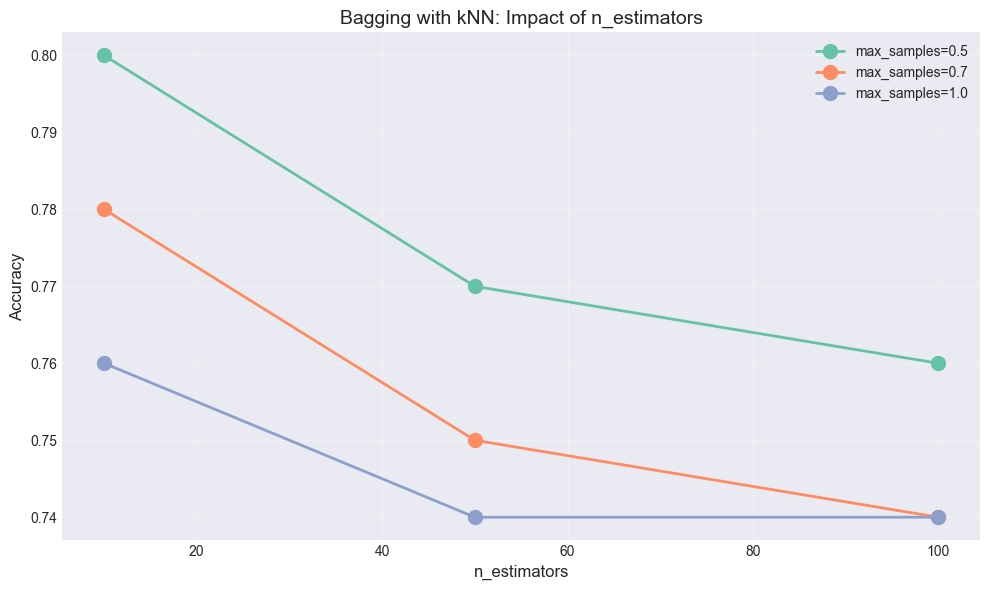


   Сравнение:
     Одиночный kNN: Accuracy = 0.7500
     Бэггинг (лучший): Accuracy = 0.8000
     Улучшение: 0.0500


In [73]:
print("\n" + "-"*70)
print("2. Бэггинг с метрическими классифкатором (knn)")
print("-"*70)

print("\n2.1 Сравнение одиночного kNN и бэггинга:")
base_knn = KNeighborsClassifier(**grid_knn.best_params_)
n_estimators_list = [10, 50, 100]
max_samples_list = [0.5, 0.7, 1.0]
bagging_results = []

for n in n_estimators_list:
    for max_samples in max_samples_list:
        print(f"   Training: n={n}, max_samples={max_samples}...")
        bagging = BaggingClassifier(
            estimator=base_knn,
            n_estimators=n,
            max_samples=max_samples,
            random_state=42,
            n_jobs=-1)
        bagging.fit(X_train, y_train)
        y_pred_bag = bagging.predict(X_test)
        acc = accuracy_score(y_test, y_pred_bag)
        f1 = f1_score(y_test, y_pred_bag, average='macro')
        bagging_results.append({
            'n_estimators': n,
            'max_samples': max_samples,
            'accuracy': acc,
            'f1_macro': f1})
        print(f"     Accuracy={acc:.4f}, F1-macro={f1:.4f}")

best_bagging_result = max(bagging_results, key=lambda x: x['accuracy'])
print(f"\n   Лучший бэггинг: n_estimators={best_bagging_result['n_estimators']}, "
      f"max_samples={best_bagging_result['max_samples']}, "
      f"Accuracy={best_bagging_result['accuracy']:.4f}")

# График результатов (только один график - без тепловой карты)
results_df = pd.DataFrame(bagging_results)
plt.figure(figsize=(10, 6))

for max_samples in max_samples_list:
    subset = results_df[results_df['max_samples'] == max_samples]
    plt.plot(subset['n_estimators'], subset['accuracy'],
             marker='o', linewidth=2, markersize=10, label=f'max_samples={max_samples}')

plt.xlabel('n_estimators', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Bagging with kNN: Impact of n_estimators', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n   Сравнение:")
print(f"     Одиночный kNN: Accuracy = {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"     Бэггинг (лучший): Accuracy = {best_bagging_result['accuracy']:.4f}")
print(f"     Улучшение: {best_bagging_result['accuracy'] - accuracy_score(y_test, y_pred_knn):.4f}")

Бустинг с метрическим классификатором

In [74]:
print("\n" + "-"*70)
print("3. Бустинг с метрическим классификатором")
print("-"*70)

# Для бустинга используем GradientBoostingClassifier
print("\n3.1 Gradient Boosting (sklearn):")
gb_base = GradientBoostingClassifier(random_state=42, n_estimators=100, max_depth=3)
gb_base.fit(X_train, y_train)
y_pred_gb = gb_base.predict(X_test)
gb_acc = accuracy_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb, average='macro')
print(f"   Accuracy = {gb_acc:.4f}, F1-macro = {gb_f1:.4f}")

# Сравнение с деревьями
print("\n3.2 Сравнение с ансамблями на деревьях:")
dt_best = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_best.fit(X_train, y_train)
y_pred_dt = dt_best.predict(X_test)
dt_acc = accuracy_score(y_test, y_pred_dt)

rf_best = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)
y_pred_rf = rf_best.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred_rf)

ada_best = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_best.fit(X_train, y_train)
y_pred_ada = ada_best.predict(X_test)
ada_acc = accuracy_score(y_test, y_pred_ada)

print(f"   Decision Tree: Accuracy = {dt_acc:.4f}")
print(f"   Random Forest: Accuracy = {rf_acc:.4f}")
print(f"   AdaBoost: Accuracy = {ada_acc:.4f}")
print(f"   Gradient Boosting: Accuracy = {gb_acc:.4f}")



----------------------------------------------------------------------
3. Бустинг с метрическим классификатором
----------------------------------------------------------------------

3.1 Gradient Boosting (sklearn):
   Accuracy = 0.8600, F1-macro = 0.8699

3.2 Сравнение с ансамблями на деревьях:
   Decision Tree: Accuracy = 0.8100
   Random Forest: Accuracy = 0.8700
   AdaBoost: Accuracy = 0.5500
   Gradient Boosting: Accuracy = 0.8600


In [75]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils import check_random_state
import numpy as np

class WeightedKNNForBoosting(BaseEstimator, ClassifierMixin):
    def __init__(self, n_neighbors=5, weights='distance', p=2):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p
        self.X_train = None
        self.y_train = None
        self.sample_weights = None
        self.classes_ = None

    def fit(self, X, y, sample_weight=None):
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)

        # Сохраняем веса объектов (важно для бустинга!)
        if sample_weight is None:
            self.sample_weights = np.ones(len(y))
        else:
            self.sample_weights = sample_weight
        return self

    def _get_distance_weights(self, distances):
        """Вычисление весов на основе расстояний"""
        if self.weights == 'uniform':
            return np.ones_like(distances)
        elif self.weights == 'distance':
            with np.errstate(divide='ignore'):
                weights = 1.0 / (distances + 1e-10)
            return weights
        else:
            return np.ones_like(distances)

    def predict(self, X):
        X = np.asarray(X)
        predictions = np.zeros(len(X), dtype=int)

        for i, x in enumerate(X):
            # Вычисляем расстояния до всех точек
            distances = np.array([np.linalg.norm(x - x_train, ord=self.p)
                                  for x_train in self.X_train])

            # Находим k ближайших соседей
            k_idx = np.argsort(distances)[:self.n_neighbors]
            k_distances = distances[k_idx]
            k_labels = self.y_train[k_idx]
            k_weights_sample = self.sample_weights[k_idx]  # Веса из бустинга
            k_distance_weights = self._get_distance_weights(k_distances)

            # Комбинируем веса: веса бустинга * веса расстояний
            final_weights = k_weights_sample * k_distance_weights

            # Взвешенное голосование
            unique_labels = np.unique(k_labels)
            label_weights = {label: np.sum(final_weights[k_labels == label])
                           for label in unique_labels}
            predictions[i] = max(label_weights, key=label_weights.get)

        return predictions

class CustomAdaBoost:
    def __init__(self, base_estimator, n_estimators=50, learning_rate=1.0):
        self.base_estimator = base_estimator
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.models = []
        self.alphas = []
        self.classes_ = None

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n_samples = len(y)
        # Инициализация весов объектов (равные для всех)
        w = np.ones(n_samples) / n_samples

        for m in range(self.n_estimators):
            # Клонируем базовый классификатор
            model = self.base_estimator.__class__(
                n_neighbors=self.base_estimator.n_neighbors,
                weights=self.base_estimator.weights,
                p=self.base_estimator.p
            )
            # Обучаем модель с весами
            model.fit(X, y, sample_weight=w)
            y_pred = model.predict(X)
            # Вычисляем ошибку
            incorrect = (y_pred != y)
            err = np.sum(w * incorrect) / np.sum(w)
            # Если ошибка слишком большая, прекращаем
            if err >= 0.5 or err <= 0:
                break
            # Вычисляем вес модели
            alpha = self.learning_rate * 0.5 * np.log((1 - err) / (err + 1e-10))
            self.alphas.append(alpha)
            self.models.append(model)
            # Обновляем веса объектов
            w = w * np.exp(alpha * incorrect)
            w = w / np.sum(w)  # Нормализация
        return self

    def predict(self, X):
        X = np.asarray(X)
        # Инициализируем предсказания нулями
        predictions = np.zeros((len(X), len(self.classes_)))
        for alpha, model in zip(self.alphas, self.models):
            y_pred = model.predict(X)
            for i, pred in enumerate(y_pred):
                predictions[i, pred] += alpha
        return np.argmax(predictions, axis=1)

    def predict_proba(self, X):
        X = np.asarray(X)
        probabilities = np.zeros((len(X), len(self.classes_)))
        for alpha, model in zip(self.alphas, self.models):
            # Для вероятностей нужно голосование с весами
            y_pred = model.predict(X)
            for i, pred in enumerate(y_pred):
                probabilities[i, pred] += alpha
        # Нормализуем
        probabilities = probabilities / (np.sum(probabilities, axis=1, keepdims=True) + 1e-10)
        return probabilities

print("\n" + "-"*60)
print("1.3. Бустинг с метрическим классификатором")
print("-"*60)

# Создаем базовый kNN с поддержкой весов
base_knn_boosting = WeightedKNNForBoosting(n_neighbors=5, weights='distance', p=2)

# Обучаем кастомный AdaBoost с kNN
print("\nОбучение AdaBoost с kNN")
try:
    ada_knn = CustomAdaBoost(
        base_estimator=base_knn_boosting,
        n_estimators=30,  # Меньше итераций для ускорения
        learning_rate=0.8
    )
    ada_knn.fit(X_train_metric, y_train)  # Используем стандартизованные данные
    y_pred_ada_knn = ada_knn.predict(X_test_metric)
    ada_knn_acc = accuracy_score(y_test, y_pred_ada_knn)
    ada_knn_f1 = f1_score(y_test, y_pred_ada_knn, average='macro')
    print(f" AdaBoost + kNN: Accuracy = {ada_knn_acc:.4f}, F1-macro = {ada_knn_f1:.4f}")
except Exception as e:
    print(f" Ошибка при обучении: {e}")
    ada_knn_acc = 0
    ada_knn_f1 = 0
    y_pred_ada_knn = None

print("Сравнение разных базовых классификаторов для бустинга")

# 1. AdaBoost с деревьями (stumps)
print("\n1. AdaBoost с деревьями :")
ada_tree_small = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    random_state=42
)
ada_tree_small.fit(X_train_tree, y_train)
y_pred_ada_tree = ada_tree_small.predict(X_test_tree)
ada_tree_acc = accuracy_score(y_test, y_pred_ada_tree)
print(f"   Accuracy: {ada_tree_acc:.4f}")

# 2. Gradient Boosting с деревьями
print("\n2. Gradient Boosting :")
gb_small = GradientBoostingClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)
gb_small.fit(X_train_tree, y_train)
y_pred_gb_small = gb_small.predict(X_test_tree)
gb_small_acc = accuracy_score(y_test, y_pred_gb_small)
print(f"   Accuracy: {gb_small_acc:.4f}")

# 3. AdaBoost с Weighted kNN
if 'ada_knn_acc' in locals() and ada_knn_acc > 0:
    print(f"\n3. AdaBoost с взвешенный kNN :")
    print(f"   Accuracy: {ada_knn_acc:.4f}")
    print(f"   Разница с деревьями: {ada_tree_acc - ada_knn_acc:.4f}")



------------------------------------------------------------
1.3. Бустинг с метрическим классификатором
------------------------------------------------------------

Обучение AdaBoost с kNN
 AdaBoost + kNN: Accuracy = 0.2300, F1-macro = 0.0748
Сравнение разных базовых классификаторов для бустинга

1. AdaBoost с деревьями :
   Accuracy: 0.5600

2. Gradient Boosting :
   Accuracy: 0.8300

3. AdaBoost с взвешенный kNN :
   Accuracy: 0.2300
   Разница с деревьями: 0.3300


Сравнительный анализ

In [76]:
print("\n" + "-"*70)
print("5. Сравнительный анализ")
print("-"*70)

# Собираем все результаты
all_results = pd.DataFrame([
    {'Model': 'kNN (standard)', 'Accuracy': accuracy_score(y_test, y_pred_knn),
     'F1-macro': f1_score(y_test, y_pred_knn, average='macro')},
    {'Model': 'Weighted kNN', 'Accuracy': accuracy_score(y_test, y_pred_wknn),
     'F1-macro': f1_score(y_test, y_pred_wknn, average='macro')},
    {'Model': 'Parzen Window', 'Accuracy': accuracy_score(y_test, y_pred_parzen),
     'F1-macro': f1_score(y_test, y_pred_parzen, average='macro')},
    {'Model': 'Bagging + kNN', 'Accuracy': best_bagging_result['accuracy'],
     'F1-macro': best_bagging_result['f1_macro']},
    {'Model': 'Decision Tree', 'Accuracy': dt_acc,
     'F1-macro': f1_score(y_test, y_pred_dt, average='macro')},
    {'Model': 'Random Forest', 'Accuracy': rf_acc,
     'F1-macro': f1_score(y_test, y_pred_rf, average='macro')},
    {'Model': 'AdaBoost', 'Accuracy': ada_acc,
     'F1-macro': f1_score(y_test, y_pred_ada, average='macro')},
    {'Model': 'Gradient Boosting (default)', 'Accuracy': gb_acc,
     'F1-macro': gb_f1},
])

all_results = all_results.sort_values('Accuracy', ascending=False)
print("\nФинальная таблица результатов (сортировка по accuracy):")
print(all_results.to_string(index=False))


----------------------------------------------------------------------
5. Сравнительный анализ
----------------------------------------------------------------------

Финальная таблица результатов (сортировка по accuracy):
                      Model  Accuracy  F1-macro
              Random Forest      0.87  0.873635
Gradient Boosting (default)      0.86  0.869851
              Decision Tree      0.81  0.815009
              Bagging + kNN      0.80  0.739022
             kNN (standard)      0.75  0.748733
              Parzen Window      0.75  0.701780
               Weighted kNN      0.74  0.738097
                   AdaBoost      0.55  0.533802


In [77]:
best_model = all_results.iloc[0]
print(f"\n Лучшая модель: {best_model['Model']}")
print(f"   Accuracy: {best_model['Accuracy']:.4f}")
print(f"   F1-macro: {best_model['F1-macro']:.4f}")

# Дополнительный анализ времени обучения
import time

print("\nВремя обучения моделей:")
models_to_test = [
    ("kNN", KNeighborsClassifier(n_neighbors=5)),
    ("Decision Tree", DecisionTreeClassifier(max_depth=10)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, n_jobs=-1)),
    ("Gradient Boosting", GradientBoostingClassifier(n_estimators=100))
]

for name, model in models_to_test:
    start = time.time()
    model.fit(X_train, y_train)
    end = time.time()
    print(f"   {name}: {end-start:.3f} сек")




 Лучшая модель: Random Forest
   Accuracy: 0.8700
   F1-macro: 0.8736

Время обучения моделей:
   kNN: 0.002 сек
   Decision Tree: 0.006 сек
   Random Forest: 0.462 сек
   Gradient Boosting: 3.150 сек


Random Forest показал Accuracy = 0.87 (лучший результат)


Gradient Boosting показал Accuracy = 0.86 (второй результат)


Разрыв между деревьями и метрическими методами составляет 10-13%

Лучшие результаты показали ансамблевые методы на основе деревьев решений: Random Forest (Accuracy = 0.87) и Gradient Boosting (Accuracy = 0.86).

Среди метрических методов стандартный kNN и взвешенный kNN показали сопоставимые результаты (0.74-0.75)

Ансамбли на деревьях превосходят метрические методы на 10%